# Midterm — Eksplorasi Data Kasus Baru TB Paru Kota Bandung

Visualisasi Data Lanjut (CAK7AGB4) · NIM 203012420009

Sumber: Dinas Kesehatan Kota Bandung, Open Data Kota Bandung —
https://opendata.bandung.go.id/dataset/jumlah-kasus-baru-tuberkolosis-paru-berdasarkan-fasilitas-kesehatan-di-kota-bandung

In [1]:
import re

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
# Data mentah (path relatif)
raw = pd.read_csv("../datasets/jumlah_kasus_baru_tuberkolosis_paru_berdasarkan_fasil.csv")
raw.shape

(1344, 10)

## A. Struktur data

In [3]:
raw.head()

,id,kode_provinsi,nama_provinsi,bps_kode_kabupaten_kota,bps_nama_kabupaten_kota,fasilitas_kesehatan,jenis_kelamin,jumlah_kasus_baru,satuan,tahun
0,1,32,JAWA BARAT,3273,KOTA BANDUNG,BBKPM,LAKI LAKI,41,ORANG,2016
1,2,32,JAWA BARAT,3273,KOTA BANDUNG,BBKPM,PEREMPUAN,33,ORANG,2016
2,3,32,JAWA BARAT,3273,KOTA BANDUNG,KLINIK SWASTA,LAKI LAKI,0,ORANG,2016
3,4,32,JAWA BARAT,3273,KOTA BANDUNG,KLINIK SWASTA,PEREMPUAN,0,ORANG,2016
4,5,32,JAWA BARAT,3273,KOTA BANDUNG,LAPAS/RUTAN,LAKI LAKI,21,ORANG,2016


In [4]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1344 entries, 0 to 1343
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   id                       1344 non-null   int64 
 1   kode_provinsi            1344 non-null   int64 
 2   nama_provinsi            1344 non-null   object
 3   bps_kode_kabupaten_kota  1344 non-null   int64 
 4   bps_nama_kabupaten_kota  1344 non-null   object
 5   fasilitas_kesehatan      1344 non-null   object
 6   jenis_kelamin            1344 non-null   object
 7   jumlah_kasus_baru        1344 non-null   int64 
 8   satuan                   1344 non-null   object
 9   tahun                    1344 non-null   int64 
dtypes: int64(5), object(5)
memory usage: 105.1+ KB


In [5]:
# Nilai kosong dan jumlah nilai unik per kolom
pd.DataFrame({"kosong": raw.isna().sum(), "unik": raw.nunique()})

,kosong,unik
id,0,1344
kode_provinsi,0,1
nama_provinsi,0,1
bps_kode_kabupaten_kota,0,1
bps_nama_kabupaten_kota,0,1
fasilitas_kesehatan,0,105
jenis_kelamin,0,3
jumlah_kasus_baru,0,106
satuan,0,1
tahun,0,10


In [6]:
# Kolom yang isinya sama untuk semua baris
[k for k in raw.columns if raw[k].nunique() == 1]

['kode_provinsi',
 'nama_provinsi',
 'bps_kode_kabupaten_kota',
 'bps_nama_kabupaten_kota',
 'satuan']

In [7]:
raw["jumlah_kasus_baru"].describe()

count    1344.000000
mean       25.304315
std        56.311537
min         0.000000
25%         8.000000
50%        14.500000
75%        26.000000
max       764.000000
Name: jumlah_kasus_baru, dtype: float64

## B. Pembersihan

In [8]:
# Ejaan jenis kelamin per tahun
raw.groupby("tahun")["jenis_kelamin"].unique()

tahun
2016    [LAKI LAKI, PEREMPUAN]
2017    [LAKI LAKI, PEREMPUAN]
2018    [LAKI LAKI, PEREMPUAN]
2019    [LAKI LAKI, PEREMPUAN]
2020    [LAKI LAKI, PEREMPUAN]
2021    [LAKI LAKI, PEREMPUAN]
2022    [LAKI-LAKI, PEREMPUAN]
2023    [LAKI-LAKI, PEREMPUAN]
2024    [LAKI-LAKI, PEREMPUAN]
2025    [LAKI-LAKI, PEREMPUAN]
Name: jenis_kelamin, dtype: object

In [9]:
df = raw[["fasilitas_kesehatan", "jenis_kelamin", "tahun", "jumlah_kasus_baru"]].copy()
df = df.rename(columns={"fasilitas_kesehatan": "faskes_asli", "jumlah_kasus_baru": "kasus"})
df["jk"] = df["jenis_kelamin"].str.replace("-", " ").map({"LAKI LAKI": "L", "PEREMPUAN": "P"})
df = df.drop(columns="jenis_kelamin")

In [10]:
# Kunci nama faskes: tanpa spasi; tiga nama yang berganti ejaan disatukan manual
ALIAS = {"UPTIBRAHIMAJI": "UPTIBRAHIMADJIE", "UPTMOCH.RAMDAN": "UPTMOHRAMDHAN", "UPTSUKAPARKIR": "UPTSUKAPAKIR"}
kunci = df["faskes_asli"].str.replace(r"\s+", "", regex=True)
df["kunci"] = kunci.replace(ALIAS)

# Nama tampilan: ejaan pada tahun terakhir kemunculannya
nama = df.sort_values("tahun").groupby("kunci")["faskes_asli"].last().str.replace(r"\s*/\s*", "/", regex=True)
df["faskes"] = df["kunci"].map(nama)

# Pasangan ejaan yang disatukan
varian = df.groupby("kunci")["faskes_asli"].unique()
varian[varian.map(len) > 1]

kunci
LAPAS/RUTAN                                [LAPAS/RUTAN, LAPAS/ RUTAN]
UPTASTANAANYAR                     [UPT ASTANAANYAR, UPT ASTANA ANYAR]
UPTBABAKANSARI                     [UPT BABAKAN SARI, UPT BABAKANSARI]
UPTBALAIKOTA                           [UPT BALAIKOTA, UPT BALAI KOTA]
UPTIBRAHIMADJIE                   [UPT IBRAHIM AJI, UPT IBRAHIM ADJIE]
UPTKARANGSETRA                     [UPT KARANGSETRA, UPT KARANG SETRA]
UPTKUJANGSARI                        [UPT KUJANGSARI, UPT KUJANG SARI]
UPTMANDALAMEKAR                  [UPT MANDALA MEKAR, UPT MANDALAMEKAR]
UPTMOHRAMDHAN                      [UPT MOCH. RAMDAN, UPT MOH RAMDHAN]
UPTPASIRJATI                           [UPT PASIRJATI, UPT PASIR JATI]
UPTPASIRKALIKI                     [UPT PASIRKALIKI, UPT PASIR KALIKI]
UPTSINDANGJAYA                     [UPT SINDANGJAYA, UPT SINDANG JAYA]
UPTSUKAPAKIR                           [UPT SUKAPARKIR, UPT SUKAPAKIR]
UPTTALAGABODAS                     [UPT TALAGABODAS, UPT TALAGA BODAS]


In [11]:
def kategori(n):
    if n.startswith("UPT"):
        return "Puskesmas"
    if n.startswith("RS") or n == "RUMAH SAKIT":
        return "Rumah sakit"
    if "BBKPM" in n:
        return "BBKPM/BKPM"
    if "KLINIK" in n or "DOKTER" in n:
        return "Klinik/DPM"
    if "LAPAS" in n:
        return "Lapas/rutan"
    return "Luar Kota Bandung"

df["kategori"] = df["faskes"].map(kategori)
df.groupby("kategori")["faskes"].unique()

kategori
BBKPM/BKPM                                     [BBKPM, BP4/BBKPM/BKPM]
Klinik/DPM           [KLINIK SWASTA, KLINIK PEMERINTAH, DOKTER PRAK...
Lapas/rutan                                              [LAPAS/RUTAN]
Luar Kota Bandung                                  [LUAR KOTA BANDUNG]
Puskesmas            [UPT ARCAMANIK, UPT BABAKAN SARI, UPT CARINGIN...
Rumah sakit                    [RUMAH SAKIT, RS PEMERINTAH, RS SWASTA]
Name: faskes, dtype: object

In [12]:
# Setiap faskes-tahun harus punya tepat satu baris L dan satu baris P
cek = df.groupby(["faskes", "tahun"])["jk"].agg(lambda s: "".join(sorted(s)))
cek[cek != "LP"]

Series([], Name: jk, dtype: object)

In [13]:
df.to_csv("../datasets/tb_bersih.csv", index=False)
df.shape

(1344, 7)

## C. Cakupan pencatatan per tahun

In [14]:
# Jumlah faskes yang tercatat per kategori
df.groupby(["kategori", "tahun"])["faskes"].nunique().unstack().fillna(0).astype(int)

tahun,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
kategori,,,,,,,,,,
BBKPM/BKPM,1,1,1,0,0,0,0,0,0,1
Klinik/DPM,1,1,1,0,0,0,0,0,0,3
Lapas/rutan,1,1,1,0,0,0,0,0,0,1
Luar Kota Bandung,0,0,0,0,0,0,1,1,1,0
Puskesmas,30,30,30,80,80,80,80,80,80,80
Rumah sakit,1,1,1,0,0,0,0,0,0,2


In [15]:
# Total kasus per kategori
per_kat = df.pivot_table(index="kategori", columns="tahun", values="kasus", aggfunc="sum")
per_kat.loc["Total"] = per_kat.sum()
per_kat.fillna("-")

tahun,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
kategori,,,,,,,,,,
BBKPM/BKPM,74.0,59.0,80.0,-,-,-,-,-,-,80.0
Klinik/DPM,0.0,4.0,7.0,-,-,-,-,-,-,21.0
Lapas/rutan,28.0,8.0,9.0,-,-,-,-,-,-,13.0
Luar Kota Bandung,-,-,-,-,-,-,550.0,751.0,998.0,-
Puskesmas,1107.0,1003.0,1100.0,7491.0,2440.0,1991.0,2093.0,3077.0,3371.0,2125.0
Rumah sakit,840.0,919.0,1135.0,-,-,-,-,-,-,2635.0
Total,2049.0,1993.0,2331.0,7491.0,2440.0,1991.0,2643.0,3828.0,4369.0,4874.0


In [16]:
# Puskesmas baru di 2019 dan puskesmas yang selalu tercatat sejak 2016
pkm = df[df["kategori"] == "Puskesmas"]
tahun_pkm = pkm.groupby("faskes")["tahun"].agg(["min", "max", "nunique"])
tahun_pkm.value_counts()

min   max   nunique
2019  2025  7          50
2016  2025  10         30
Name: count, dtype: int64

## D. Tren total

In [17]:
pkm_tahun = pkm.groupby("tahun")["kasus"].sum()
lama = tahun_pkm.index[tahun_pkm["min"] == 2016]
pkm_lama = pkm[pkm["faskes"].isin(lama)].groupby("tahun")["kasus"].sum()

tren = pd.DataFrame({
    "semua faskes": df.groupby("tahun")["kasus"].sum(),
    "puskesmas": pkm_tahun,
    "30 puskesmas sejak 2016": pkm_lama,
})
tren

,semua faskes,puskesmas,30 puskesmas sejak 2016
tahun,,,
2016,2049,1107,1107
2017,1993,1003,1003
2018,2331,1100,1100
2019,7491,7491,3870
2020,2440,2440,1277
2021,1991,1991,1045
2022,2643,2093,1071
2023,3828,3077,1520
2024,4369,3371,1734


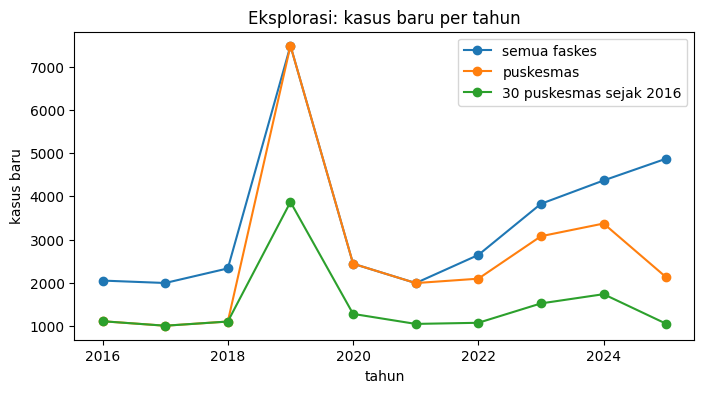

In [18]:
ax = tren.plot(marker="o", figsize=(8, 4))
ax.set_ylabel("kasus baru")
ax.set_title("Eksplorasi: kasus baru per tahun")
plt.show()

## E. Antar puskesmas

In [19]:
# Sebaran kasus per puskesmas per tahun
pkm_ft = pkm.groupby(["faskes", "tahun"])["kasus"].sum().unstack()
pkm_ft.describe().round(1)

tahun,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
count,30.0,30.0,30.0,80.0,80.0,80.0,80.0,80.0,80.0,80.0
mean,36.9,33.4,36.7,93.6,30.5,24.9,26.2,38.5,42.1,26.6
std,23.3,20.4,22.4,63.3,21.4,20.4,20.7,26.4,29.5,19.0
min,4.0,2.0,7.0,10.0,4.0,2.0,1.0,6.0,4.0,4.0
25%,19.0,18.0,20.0,48.0,15.8,11.0,11.0,19.0,19.8,13.0
50%,35.5,30.0,32.5,83.5,26.0,17.0,20.0,31.5,33.0,21.0
75%,50.2,46.0,44.0,125.0,37.5,32.2,32.2,50.2,54.0,33.5
max,92.0,98.0,92.0,354.0,116.0,114.0,98.0,116.0,126.0,103.0


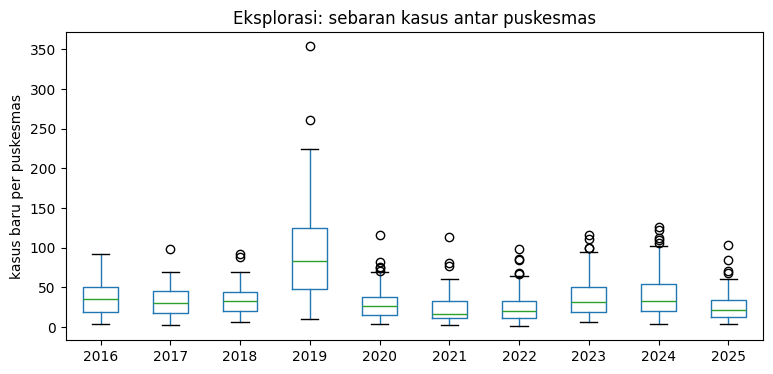

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
pkm_ft.boxplot(ax=ax, grid=False)
ax.set_ylabel("kasus baru per puskesmas")
ax.set_title("Eksplorasi: sebaran kasus antar puskesmas")
plt.show()

In [21]:
# Rasio 2019 terhadap 2018 untuk 30 puskesmas lama
(pkm_ft.loc[lama, 2019] / pkm_ft.loc[lama, 2018]).describe().round(2)

count    30.00
mean      4.35
std       2.83
min       0.77
25%       2.23
50%       3.46
75%       6.27
max      13.43
dtype: float64

In [22]:
# Periode 80 puskesmas tanpa 2019: 2020-2025
P = [2020, 2021, 2022, 2023, 2024, 2025]
panel = pkm_ft[P].dropna()
panel["total"] = panel.sum(axis=1)
panel.sort_values("total", ascending=False).head(10)

tahun,2020,2021,2022,2023,2024,2025,total
faskes,,,,,,,
UPT GARUDA,76.0,114.0,98.0,116.0,110.0,103.0,617.0
UPT BABAKAN SARI,116.0,77.0,68.0,111.0,101.0,48.0,521.0
UPT SUKAHAJI,69.0,56.0,84.0,100.0,126.0,71.0,506.0
UPT CARINGIN,69.0,52.0,86.0,100.0,112.0,85.0,504.0
UPT SUKAJADI,69.0,81.0,64.0,67.0,122.0,68.0,471.0
UPT CETARIP,71.0,61.0,52.0,95.0,106.0,59.0,444.0
UPT PASIR KALIKI,55.0,49.0,67.0,86.0,102.0,61.0,420.0
UPT MARGAHAYU RAYA,75.0,38.0,51.0,82.0,83.0,51.0,380.0
UPT GUMURUH,44.0,41.0,54.0,93.0,84.0,55.0,371.0


In [23]:
panel.sort_values("total").head(10)

tahun,2020,2021,2022,2023,2024,2025,total
faskes,,,,,,,
UPT SURYALAYA,4.0,2.0,2.0,6.0,8.0,8.0,30.0
UPT GIRIMANDE,6.0,6.0,3.0,8.0,4.0,5.0,32.0
UPT SALAM,5.0,7.0,1.0,10.0,4.0,11.0,38.0
UPT CEMPAKA ARUM,10.0,3.0,8.0,8.0,10.0,4.0,43.0
UPT LIOGENTENG,6.0,3.0,5.0,12.0,14.0,6.0,46.0
UPT CIJAGRA BARU,13.0,7.0,3.0,7.0,11.0,10.0,51.0
UPT CIPAKU,6.0,6.0,9.0,10.0,15.0,11.0,57.0
UPT PANYILEUKAN,8.0,4.0,9.0,13.0,11.0,13.0,58.0
UPT PAMULANG,6.0,6.0,4.0,11.0,13.0,20.0,60.0


In [24]:
# Porsi kasus: 10 puskesmas teratas terhadap semua puskesmas, 2020-2025
top10 = panel["total"].nlargest(10).sum() / panel["total"].sum()
round(top10, 3)

np.float64(0.304)

In [25]:
# Perubahan 2020 ke 2024 per puskesmas
ubah = (panel[2024] - panel[2020]).sort_values()
pd.concat([ubah.head(5), ubah.tail(5)])

faskes
UPT BABAKAN SARI         -15.0
UPT UJUNG BERUNG INDAH   -14.0
UPT ANTAPANI             -12.0
UPT TAMANSARI            -11.0
UPT CIBADUYUT WETAN       -6.0
UPT CARINGIN              43.0
UPT PASIR KALIKI          47.0
UPT CIGONDEWAH            50.0
UPT SUKAJADI              53.0
UPT SUKAHAJI              57.0
dtype: float64

In [26]:
# Konsistensi peringkat antar tahun (korelasi Spearman)
panel[P].corr(method="spearman").round(2)

tahun,2020,2021,2022,2023,2024,2025
tahun,,,,,,
2020,1.00,0.84,0.87,0.85,0.85,0.77
2021,0.84,1.00,0.87,0.88,0.88,0.79
2022,0.87,0.87,1.00,0.92,0.93,0.87
2023,0.85,0.88,0.92,1.00,0.93,0.88
2024,0.85,0.88,0.93,0.93,1.00,0.89
2025,0.77,0.79,0.87,0.88,0.89,1.00


## F. Jenis kelamin

In [27]:
jk = df.pivot_table(index="tahun", columns="jk", values="kasus", aggfunc="sum")
jk["porsi_L"] = (jk["L"] / (jk["L"] + jk["P"])).round(3)
jk

jk,L,P,porsi_L
tahun,,,
2016,1108,941,0.541
2017,1075,918,0.539
2018,1286,1045,0.552
2019,3791,3700,0.506
2020,1212,1228,0.497
2021,1022,969,0.513
2022,1362,1281,0.515
2023,2063,1765,0.539
2024,2312,2057,0.529


In [28]:
# Porsi laki-laki per kategori, seluruh tahun
k = df.pivot_table(index="kategori", columns="jk", values="kasus", aggfunc="sum")
(k["L"] / k.sum(axis=1)).round(3).sort_values()

kategori
Klinik/DPM           0.312
Puskesmas            0.519
BBKPM/BKPM           0.529
Luar Kota Bandung    0.545
Rumah sakit          0.548
Lapas/rutan          0.862
dtype: float64

In [29]:
# Puskesmas dengan porsi laki-laki paling ekstrem, 2020-2025
pj = pkm[pkm["tahun"].isin(P)].pivot_table(index="faskes", columns="jk", values="kasus", aggfunc="sum")
pj["porsi_L"] = (pj["L"] / pj.sum(axis=1)).round(3)
pd.concat([pj.nsmallest(5, "porsi_L"), pj.nlargest(5, "porsi_L")])

jk,L,P,porsi_L
faskes,,,
UPT SUKARASA,52,85,0.380
UPT SARIJADI,53,74,0.417
UPT CIPAKU,24,33,0.421
UPT JATIHANDAP,33,45,0.423
UPT PASAWAHAN,28,38,0.424
UPT CIJAGRA BARU,34,17,0.667
UPT SURYALAYA,20,10,0.667
UPT DERWATI,83,55,0.601
UPT PAGARSIH,86,61,0.585


## G. Angka untuk Message Brief

In [30]:
# Pesan utama: kenaikan 2021-2024 dan penurunan 2025
pt = panel[P].sum()
pt, round(pt[2024] / pt[2021] - 1, 3)

(tahun
 2020    2440.0
 2021    1991.0
 2022    2093.0
 2023    3077.0
 2024    3371.0
 2025    2125.0
 dtype: float64,
 np.float64(0.693))

In [31]:
# 21 puskesmas dengan total kasus tertinggi 2020-2025 (separuh kasus)
porsi = panel["total"].sort_values(ascending=False).cumsum() / panel["total"].sum()
top21 = porsi.index[:21]
porsi.head(21).round(3)

faskes
UPT GARUDA                0.041
UPT BABAKAN SARI          0.075
UPT SUKAHAJI              0.109
UPT CARINGIN              0.142
UPT SUKAJADI              0.173
UPT CETARIP               0.203
UPT PASIR KALIKI          0.231
UPT MARGAHAYU RAYA        0.256
UPT GUMURUH               0.280
UPT DAGO                  0.304
UPT KOPO                  0.327
UPT PADASUKA              0.351
UPT BABAKAN TAROGONG      0.373
UPT CIBUNTU               0.394
UPT IBRAHIM ADJIE         0.413
UPT PUTER                 0.431
UPT CIUMBULEUIT           0.450
UPT UJUNG BERUNG INDAH    0.467
UPT SUKAPAKIR             0.483
UPT CIJERAH               0.499
UPT KUJANG SARI           0.514
Name: total, dtype: float64

In [32]:
# Klaim 2: porsi 21 puskesmas tersebut per tahun
(panel.loc[top21, P].sum() / panel[P].sum()).round(3)

tahun
2020    0.509
2021    0.543
2022    0.535
2023    0.503
2024    0.508
2025    0.496
dtype: float64

In [33]:
# Klaim 1: puskesmas yang naik dan turun dari 2021 ke 2024
naik = panel[2024] - panel[2021]
(naik > 0).sum(), (naik < 0).sum(), (naik == 0).sum()

(np.int64(74), np.int64(6), np.int64(0))

In [34]:
# Klaim 3: 10 puskesmas teratas 2020-2022 vs 2023-2025
a = panel[[2020, 2021, 2022]].sum(axis=1).nlargest(10).index
b = panel[[2023, 2024, 2025]].sum(axis=1).nlargest(10).index
len(a.intersection(b)), sorted(a.difference(b)), sorted(b.difference(a))

(9, ['UPT DAGO'], ['UPT GUMURUH'])

## H. Catatan untuk keterbatasan data

- Puskesmas tercatat 30 (2016–2018) lalu 80 (2019–2025).
- Tidak ada jumlah penduduk wilayah kerja puskesmas, jadi hanya jumlah kasus, bukan angka per penduduk.